In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('KERAS_HOME', str(Path.cwd() / '.keras'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from IPython.display import display


2026-10-27 00:09:07.162260: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793039947.175416    3080 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793039947.178946    3080 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793039947.188215    3080 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793039947.188254    3080 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793039947.188255    3080 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
QUICK_RUN = False
EPOCHS = 1 if QUICK_RUN else 10
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

import time
import tracemalloc
from PIL import Image, ImageFilter
OUTPUT_DIR = Path('outputs/exp04')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_LIMIT = 3000 if QUICK_RUN else 50000
OPT_SAMPLES = 256 if QUICK_RUN else 6000
SEARCH_SAMPLES = 1000 if QUICK_RUN else 8000
BATCH_SIZE = 128


TensorFlow: 2.19.1
GPUs: []


E0000 00:00:1793039950.872721    3080 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793039950.874694    3080 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
def early_stopping(patience=5):
    return keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    )


In [4]:
(x_pool, y_pool), (x_test_raw, y_test) = keras.datasets.mnist.load_data()
x_train_raw, x_val_raw, y_train, y_val = train_test_split(
    x_pool,
    y_pool,
    train_size=TRAIN_LIMIT,
    stratify=y_pool,
    random_state=SEED,
)
if QUICK_RUN:
    x_val_raw, y_val = (x_val_raw[:500], y_val[:500])
    x_test_raw, y_test = (x_test_raw[:500], y_test[:500])


In [5]:
def clean(images, labels):
    valid = np.isfinite(images).all(axis=(1, 2)) & (labels >= 0) & (labels < 10)
    images = np.clip(images[valid], 0, 255).astype('uint8')
    return (images.astype('float32')[..., None] / 255.0, labels[valid])


In [6]:
x_train, y_train = clean(x_train_raw, y_train)
x_val, y_val = clean(x_val_raw, y_val)
x_test, y_test = clean(x_test_raw, y_test)


In [7]:
def engineered_features(images):
    filtered_images = []
    for image in images:
        pixels = (image[..., 0] * 255).astype('uint8')
        image = Image.fromarray(pixels)
        filtered = image.filter(ImageFilter.MedianFilter(3))
        filtered_images.append(np.asarray(filtered))
    denoised = np.stack(filtered_images)
    denoised = denoised.astype('float32')[..., None] / 255.0
    denoised_tensor = tf.convert_to_tensor(denoised, dtype=tf.float32)
    edges = tf.image.sobel_edges(denoised_tensor).numpy()
    edges = np.sqrt(np.sum(edges ** 2, axis=-1))
    edges /= np.maximum(edges.max(axis=(1, 2, 3), keepdims=True), 1e-08)
    return np.concatenate([denoised, edges], axis=-1).astype('float32')


In [8]:
x_train_feat = engineered_features(x_train)
x_val_feat = engineered_features(x_val)
x_test_feat = engineered_features(x_test)
augmenter = keras.Sequential(
    [
        layers.RandomRotation(0.028, fill_mode='constant', seed=SEED),
        layers.RandomTranslation(0.08, 0.08, fill_mode='constant', seed=SEED),
        layers.RandomZoom(0.08, fill_mode='constant', seed=SEED),
    ],
)


In [9]:
def dataset(x, y, batch_size=BATCH_SIZE, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(min(len(x), 10000), seed=SEED)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(
            lambda images, labels: (augmenter(images, training=True), labels),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    return ds.prefetch(tf.data.AUTOTUNE)


In [10]:
print(
    'Train:',
    x_train_feat.shape,
    'Validation:',
    x_val_feat.shape,
    'Test:',
    x_test_feat.shape,
)


Train: (50000, 28, 28, 2) Validation: (10000, 28, 28, 2) Test: (10000, 28, 28, 2)


In [11]:
def build_dense():
    return keras.Sequential(
        [
            layers.Input((28, 28, 1)),
            layers.Flatten(),
            layers.Dense(128, activation='relu'),
            layers.Dense(10),
        ],
        name='dense_baseline',
    )


In [12]:
def compile_model(model, optimizer):
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )
    return model


In [13]:
baseline = compile_model(build_dense(), keras.optimizers.SGD(0.01))
baseline.fit(
    dataset(x_train, y_train),
    validation_data=dataset(x_val, y_val),
    epochs=EPOCHS,
    verbose=2,
    callbacks=[early_stopping(patience=2)],
)
indices = np.random.default_rng(SEED).choice(
    len(x_train),
    min(OPT_SAMPLES, len(x_train)),
    replace=False,
)
x_opt, y_opt = (x_train[indices], y_train[indices])
initial_weights = build_dense().get_weights()
configs = {
    'Batch GD': (lambda: keras.optimizers.SGD(0.01), len(x_opt)),
    'Stochastic GD': (lambda: keras.optimizers.SGD(0.01), 1),
    'Mini-batch GD': (lambda: keras.optimizers.SGD(0.01), 32),
    'Momentum': (lambda: keras.optimizers.SGD(0.01, momentum=0.9), 32),
    'AdaGrad': (lambda: keras.optimizers.Adagrad(0.01), 32),
    'RMSProp': (lambda: keras.optimizers.RMSprop(0.001), 32),
    'Adam': (lambda: keras.optimizers.Adam(0.001), 32),
}
optimizer_rows = []
optimizer_histories = {}


Epoch 1/10


/home/omkard/Desktop/Dev/dl_exp/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


391/391 - 1s - 3ms/step - accuracy: 0.6998 - loss: 1.2499 - val_accuracy: 0.8381 - val_loss: 0.7272
Epoch 2/10
391/391 - 1s - 2ms/step - accuracy: 0.8606 - loss: 0.5921 - val_accuracy: 0.8734 - val_loss: 0.5092
Epoch 3/10
391/391 - 1s - 2ms/step - accuracy: 0.8820 - loss: 0.4633 - val_accuracy: 0.8868 - val_loss: 0.4327
Epoch 4/10
391/391 - 1s - 2ms/step - accuracy: 0.8924 - loss: 0.4075 - val_accuracy: 0.8950 - val_loss: 0.3924
Epoch 5/10
391/391 - 1s - 2ms/step - accuracy: 0.8989 - loss: 0.3748 - val_accuracy: 0.8991 - val_loss: 0.3666
Epoch 6/10
391/391 - 1s - 2ms/step - accuracy: 0.9036 - loss: 0.3524 - val_accuracy: 0.9045 - val_loss: 0.3481
Epoch 7/10
391/391 - 1s - 2ms/step - accuracy: 0.9069 - loss: 0.3354 - val_accuracy: 0.9082 - val_loss: 0.3337
Epoch 8/10
391/391 - 1s - 2ms/step - accuracy: 0.9098 - loss: 0.3218 - val_accuracy: 0.9113 - val_loss: 0.3220
Epoch 9/10
391/391 - 1s - 2ms/step - accuracy: 0.9126 - loss: 0.3103 - val_accuracy: 0.9143 - val_loss: 0.3121
Epoch 10/10


In [14]:
for name, (factory, batch_size) in configs.items():
    keras.utils.set_random_seed(SEED)
    model = compile_model(build_dense(), factory())
    model.set_weights(initial_weights)
    start = time.perf_counter()
    history = model.fit(
        dataset(x_opt, y_opt, batch_size),
        validation_data=dataset(x_val, y_val),
        epochs=EPOCHS,
        verbose=2,
        callbacks=[early_stopping(patience=3)],
    )
    seconds = time.perf_counter() - start
    _, accuracy = model.evaluate(dataset(x_test, y_test), verbose=0)
    optimizer_rows.append(
        {
            'Optimizer': name,
            'Batch size': batch_size,
            'Epochs': len(history.history['loss']),
            'Updates': len(history.history['loss'])
            * int(np.ceil(len(x_opt) / batch_size)),
            'Test accuracy': accuracy,
            'Best validation accuracy': max(history.history['val_accuracy']),
            'Best epoch': int(np.argmax(history.history['val_accuracy'])) + 1,
            'Training seconds': seconds,
        },
    )
    optimizer_histories[name] = history.history


Epoch 1/10
1/1 - 0s - 437ms/step - accuracy: 0.0940 - loss: 2.4020 - val_accuracy: 0.0923 - val_loss: 2.3812
Epoch 2/10
1/1 - 0s - 136ms/step - accuracy: 0.0960 - loss: 2.3872 - val_accuracy: 0.0954 - val_loss: 2.3675
Epoch 3/10
1/1 - 0s - 141ms/step - accuracy: 0.0993 - loss: 2.3732 - val_accuracy: 0.0988 - val_loss: 2.3544
Epoch 4/10
1/1 - 0s - 147ms/step - accuracy: 0.1038 - loss: 2.3597 - val_accuracy: 0.1040 - val_loss: 2.3417
Epoch 5/10
1/1 - 0s - 130ms/step - accuracy: 0.1077 - loss: 2.3467 - val_accuracy: 0.1091 - val_loss: 2.3295
Epoch 6/10
1/1 - 0s - 131ms/step - accuracy: 0.1107 - loss: 2.3343 - val_accuracy: 0.1142 - val_loss: 2.3178
Epoch 7/10
1/1 - 0s - 123ms/step - accuracy: 0.1150 - loss: 2.3222 - val_accuracy: 0.1200 - val_loss: 2.3064
Epoch 8/10
1/1 - 0s - 129ms/step - accuracy: 0.1185 - loss: 2.3105 - val_accuracy: 0.1247 - val_loss: 2.2953
Epoch 9/10
1/1 - 0s - 136ms/step - accuracy: 0.1233 - loss: 2.2992 - val_accuracy: 0.1309 - val_loss: 2.2845
Epoch 10/10
1/1 - 0

,Batch size,Epochs,Updates,Test accuracy,Best validation accuracy,Best epoch,Training seconds
Optimizer,,,,,,,
Batch GD,6000,10,10,0.1384,0.1372,10,1.6949
Stochastic GD,1,10,60000,0.9452,0.9442,10,46.9444
Mini-batch GD,32,10,1880,0.8968,0.8931,10,2.8483
Momentum,32,10,1880,0.9321,0.9335,10,3.1152
AdaGrad,32,10,1880,0.9137,0.9126,10,3.4082
RMSProp,32,10,1880,0.9260,0.9292,10,3.5135
Adam,32,10,1880,0.9383,0.9396,8,3.7558


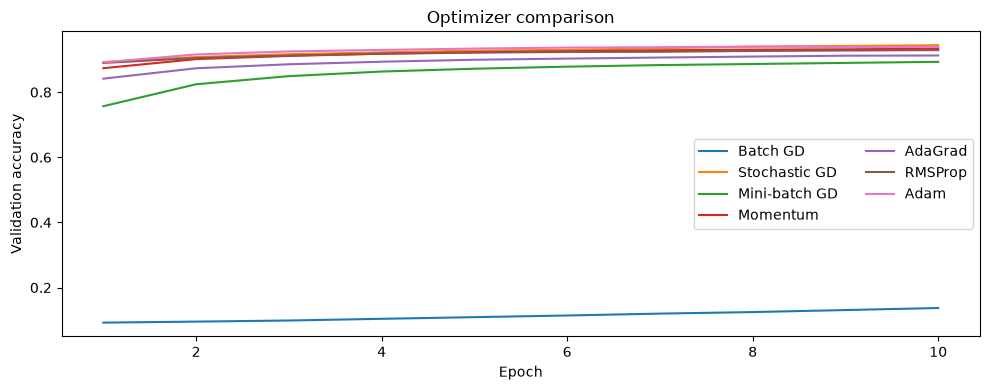

In [15]:
optimizer_table = pd.DataFrame(optimizer_rows).set_index('Optimizer')
optimizer_table.to_csv(OUTPUT_DIR / 'optimizer_comparison.csv')
display(optimizer_table.round(4))
fig, ax = plt.subplots(figsize=(10, 4))
for name, history in optimizer_histories.items():
    epochs = range(1, len(history['val_accuracy']) + 1)
    ax.plot(epochs, history['val_accuracy'], label=name)
ax.set(xlabel='Epoch', ylabel='Validation accuracy', title='Optimizer comparison')
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'optimizer_comparison.png', dpi=150)
plt.show()


In [16]:
def build_cnn(dropout=0.3, l2=0.0001):
    penalty = regularizers.l2(l2)
    inputs = keras.Input((28, 28, 2))
    x = layers.Conv2D(
        32,
        3,
        padding='same',
        activation='relu',
        kernel_regularizer=penalty,
    )(
        inputs,
    )
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    shortcut = layers.Conv2D(64, 1, padding='same')(x)
    residual = layers.Conv2D(
        64,
        3,
        padding='same',
        activation='relu',
        kernel_regularizer=penalty,
    )(
        x,
    )
    residual = layers.BatchNormalization()(residual)
    residual = layers.Conv2D(64, 3, padding='same', kernel_regularizer=penalty)(
        residual,
    )
    residual = layers.BatchNormalization()(residual)
    x = layers.Activation('relu')(layers.Add()([shortcut, residual]))
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=penalty)(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(inputs, layers.Dense(10)(x), name='residual_cnn')


In [17]:
def optimizer_for(config):
    if config['optimizer'] == 'Adam':
        return keras.optimizers.Adam(config['lr'])
    return keras.optimizers.RMSprop(config['lr'])


In [18]:
grid = [
    {
        'optimizer': 'Adam',
        'lr': 0.001,
        'batch_size': 128,
        'dropout': 0.3,
        'l2': 0.0001,
    },
    {
        'optimizer': 'Adam',
        'lr': 0.0005,
        'batch_size': 64,
        'dropout': 0.4,
        'l2': 0.0001,
    },
    {
        'optimizer': 'RMSProp',
        'lr': 0.001,
        'batch_size': 128,
        'dropout': 0.3,
        'l2': 0.0005,
    },
]
search_idx = np.random.default_rng(SEED).choice(
    len(x_train_feat),
    min(SEARCH_SAMPLES, len(x_train_feat)),
    replace=False,
)
search_rows = []


In [19]:
for config in grid:
    keras.utils.set_random_seed(SEED)
    model = compile_model(
        build_cnn(config['dropout'], config['l2']),
        optimizer_for(config),
    )
    history = model.fit(
        dataset(
            x_train_feat[search_idx],
            y_train[search_idx],
            config['batch_size'],
            True,
        ),
        validation_data=dataset(x_val_feat, y_val),
        epochs=EPOCHS,
        verbose=2,
        callbacks=[early_stopping(patience=2)],
    )
    search_rows.append(
        {**config, 'Validation accuracy': max(history.history['val_accuracy'])},
    )


Epoch 1/10


/home/omkard/Desktop/Dev/dl_exp/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 - 11s - 177ms/step - accuracy: 0.6101 - loss: 1.2637 - val_accuracy: 0.3428 - val_loss: 2.1262
Epoch 2/10
63/63 - 8s - 121ms/step - accuracy: 0.8586 - loss: 0.4879 - val_accuracy: 0.1609 - val_loss: 2.1178
Epoch 3/10
63/63 - 8s - 120ms/step - accuracy: 0.8988 - loss: 0.3593 - val_accuracy: 0.1097 - val_loss: 2.1869
Epoch 4/10
63/63 - 8s - 121ms/step - accuracy: 0.9205 - loss: 0.3025 - val_accuracy: 0.1155 - val_loss: 2.4148
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
Epoch 1/10
125/125 - 9s - 73ms/step - accuracy: 0.5437 - loss: 1.3909 - val_accuracy: 0.4646 - val_loss: 2.0374
Epoch 2/10
125/125 - 7s - 59ms/step - accuracy: 0.8181 - loss: 0.5951 - val_accuracy: 0.1773 - val_loss: 2.0205
Epoch 3/10
125/125 - 7s - 59ms/step - accuracy: 0.8765 - loss: 0.4322 - val_accuracy: 0.2709 - val_loss: 1.7987
Epoch 4/10
125/125 - 7s - 59ms/step - accuracy: 0.9011 - loss: 0.3589 - val_accuracy: 0.8689 - val_loss: 0.4653
Epoch 5/10
125/125 - 7s - 59ms/step

In [20]:
search_table = pd.DataFrame(search_rows).sort_values(
    'Validation accuracy',
    ascending=False,
)
search_table.to_csv(OUTPUT_DIR / 'hyperparameter_search.csv', index=False)
display(search_table)
best_config = grid[int(search_table.index[0])]
print('Selected:', best_config)
final_model = compile_model(
    build_cnn(best_config['dropout'], best_config['l2']),
    optimizer_for(best_config),
)
train_ds = dataset(x_train_feat, y_train, best_config['batch_size'], True)
val_ds = dataset(x_val_feat, y_val)
final_history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=2,
    callbacks=[
        early_stopping(patience=4),
        keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-06),
    ],
)
final_model.save(OUTPUT_DIR / 'teacher.keras')


,optimizer,lr,batch_size,dropout,l2,Validation accuracy
1,Adam,0.0005,64,0.4,0.0001,0.9752
2,RMSProp,0.0010,128,0.3,0.0005,0.5536
0,Adam,0.0010,128,0.3,0.0001,0.3428


Selected: {'optimizer': 'Adam', 'lr': 0.0005, 'batch_size': 64, 'dropout': 0.4, 'l2': 0.0001}
Epoch 1/10


/home/omkard/Desktop/Dev/dl_exp/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 - 42s - 54ms/step - accuracy: 0.8273 - loss: 0.5739 - val_accuracy: 0.9645 - val_loss: 0.1527 - learning_rate: 5.0000e-04
Epoch 2/10
782/782 - 37s - 47ms/step - accuracy: 0.9467 - loss: 0.2160 - val_accuracy: 0.9778 - val_loss: 0.1149 - learning_rate: 5.0000e-04
Epoch 3/10
782/782 - 29s - 37ms/step - accuracy: 0.9614 - loss: 0.1665 - val_accuracy: 0.9838 - val_loss: 0.0878 - learning_rate: 5.0000e-04
Epoch 4/10
782/782 - 29s - 37ms/step - accuracy: 0.9673 - loss: 0.1454 - val_accuracy: 0.9860 - val_loss: 0.0843 - learning_rate: 5.0000e-04
Epoch 5/10
782/782 - 29s - 37ms/step - accuracy: 0.9712 - loss: 0.1329 - val_accuracy: 0.9866 - val_loss: 0.0882 - learning_rate: 5.0000e-04
Epoch 6/10
782/782 - 29s - 37ms/step - accuracy: 0.9749 - loss: 0.1220 - val_accuracy: 0.9854 - val_loss: 0.0948 - learning_rate: 5.0000e-04
Epoch 7/10
782/782 - 29s - 37ms/step - accuracy: 0.9805 - loss: 0.1044 - val_accuracy: 0.9882 - val_loss: 0.0756 - learning_rate: 2.5000e-04
Epoch 8/10
782/782 - 29s

In [21]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, metric in zip(axes, ('accuracy', 'loss')):
        if metric not in history.history:
            ax.axis('off')
            continue
        epochs = np.arange(1, len(history.history[metric]) + 1)
        ax.plot(epochs, history.history[metric], label='Train')
        ax.plot(epochs, history.history['val_' + metric], label='Validation')
        ax.set(title=f'{title}: {metric}', xlabel='Epoch', ylabel=metric.title())
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


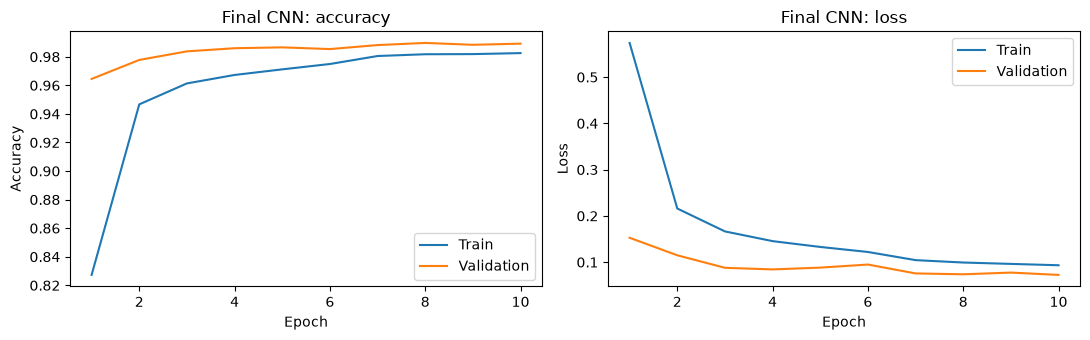

In [22]:
plot_history(final_history, 'Final CNN')


In [23]:
pruned_model = keras.models.clone_model(final_model)
pruned_model.set_weights(final_model.get_weights())
masks = []
for layer in pruned_model.layers:
    if isinstance(layer, (layers.Conv2D, layers.Dense)):
        weights = layer.kernel.numpy()
        mask = np.ones(weights.size, dtype='float32')
        mask[np.argsort(np.abs(weights).ravel())[:weights.size // 2]] = 0
        masks.append((layer.kernel, tf.constant(mask.reshape(weights.shape))))


In [24]:
class PreserveMasks(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.apply_masks()

    def on_train_batch_end(self, batch, logs=None):
        self.apply_masks()

    def apply_masks(self):
        for variable, mask in masks:
            variable.assign(variable * mask)


In [25]:
compile_model(pruned_model, keras.optimizers.Adam(best_config['lr'] / 2))
pruned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[PreserveMasks(), early_stopping(patience=2)],
    verbose=2,
)
zeros = sum((np.count_nonzero(variable.numpy() == 0) for variable, _ in masks))
total = sum((int(np.prod(variable.shape)) for variable, _ in masks))
assert all(
    (np.all(variable.numpy()[mask.numpy() == 0] == 0) for variable, mask in masks),
)
print(f'Kernel sparsity: {zeros / total:.1%}')
pruned_model.save(OUTPUT_DIR / 'pruned.keras')


Epoch 1/10
782/782 - 32s - 41ms/step - accuracy: 0.9809 - loss: 0.0956 - val_accuracy: 0.9886 - val_loss: 0.0755
Epoch 2/10
782/782 - 31s - 39ms/step - accuracy: 0.9828 - loss: 0.0882 - val_accuracy: 0.9903 - val_loss: 0.0666
Epoch 3/10
782/782 - 44s - 56ms/step - accuracy: 0.9846 - loss: 0.0841 - val_accuracy: 0.9895 - val_loss: 0.0695
Epoch 4/10
782/782 - 50s - 64ms/step - accuracy: 0.9851 - loss: 0.0813 - val_accuracy: 0.9881 - val_loss: 0.0706
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
Kernel sparsity: 50.0%


In [26]:
export_dir = OUTPUT_DIR / 'pruned_saved_model'
pruned_model.export(str(export_dir))
float_converter = tf.lite.TFLiteConverter.from_saved_model(str(export_dir))
float_tflite = float_converter.convert()
(OUTPUT_DIR / 'reference_float.tflite').write_bytes(float_tflite)


INFO:tensorflow:Assets written to: outputs/exp04/pruned_saved_model/assets


INFO:tensorflow:Assets written to: outputs/exp04/pruned_saved_model/assets


Saved artifact at 'outputs/exp04/pruned_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 2), dtype=tf.float32, name='keras_tensor_91')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  140318380842384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380843920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380842576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380842192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380843152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380842960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380842000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380843728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380839312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140318380845072: TensorSpec(shape=(), dtype=tf.resource, name=None

W0000 00:00:1793040644.032236    3080 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793040644.032269    3080 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1793040644.045356    3080 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled


1851112

In [27]:
def representative_dataset():
    for image in x_train_feat[:min(200, len(x_train_feat))]:
        (((yield [image[None].astype('float32')])))


In [28]:
converter = tf.lite.TFLiteConverter.from_saved_model(str(export_dir))
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
quantized_tflite = converter.convert()
(OUTPUT_DIR / 'quantized_int8.tflite').write_bytes(quantized_tflite)
print(f'Float TFLite: {len(float_tflite) / 1024:.1f} KiB')
print(f'Int8 TFLite: {len(quantized_tflite) / 1024:.1f} KiB')
print(f'Size reduction: {1 - len(quantized_tflite) / len(float_tflite):.1%}')


W0000 00:00:1793040644.952288    3080 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793040644.952304    3080 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.


Float TFLite: 1807.7 KiB
Int8 TFLite: 466.9 KiB
Size reduction: 74.2%


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


In [29]:
TEMPERATURE, ALPHA = (4.0, 0.1)
teacher_logits = final_model.predict(x_train_feat, verbose=0)
soft_targets = tf.nn.softmax(teacher_logits / TEMPERATURE).numpy()
packed_targets = np.concatenate(
    [keras.utils.to_categorical(y_train, 10), soft_targets],
    axis=1,
).astype(
    'float32',
)
student = keras.Sequential(
    [
        layers.Input((28, 28, 2)),
        layers.Conv2D(16, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dense(10),
    ],
    name='student_cnn',
)


In [30]:
distillation_kl = keras.losses.KLDivergence(reduction='none')


def distillation_loss(targets, logits):
    hard_loss = keras.losses.categorical_crossentropy(
        targets[:, :10],
        logits,
        from_logits=True,
    )
    soft_loss = distillation_kl(
        targets[:, 10:],
        tf.nn.softmax(logits / TEMPERATURE),
    )
    return ALPHA * hard_loss + (1 - ALPHA) * TEMPERATURE ** 2 * soft_loss


In [31]:
def hard_accuracy(targets, logits):
    return keras.metrics.categorical_accuracy(targets[:, :10], logits)


In [32]:
student.compile(optimizer='adam', loss=distillation_loss, metrics=[hard_accuracy])
student_ds = tf.data.Dataset.from_tensor_slices((x_train_feat, packed_targets))
student_ds = student_ds.shuffle(len(y_train), seed=SEED)
student_ds = student_ds.batch(BATCH_SIZE)
student_ds = student_ds.prefetch(tf.data.AUTOTUNE)
validation_logits = final_model.predict(x_val_feat, verbose=0)
validation_soft_targets = tf.nn.softmax(validation_logits / TEMPERATURE).numpy()
packed_validation_targets = np.concatenate(
    [keras.utils.to_categorical(y_val, 10), validation_soft_targets],
    axis=1,
).astype('float32')
student_val_ds = tf.data.Dataset.from_tensor_slices(
    (x_val_feat, packed_validation_targets),
)
student_val_ds = student_val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
student.fit(
    student_ds,
    validation_data=student_val_ds,
    epochs=EPOCHS,
    verbose=2,
    callbacks=[early_stopping(patience=2)],
)
compile_model(student, keras.optimizers.Adam())
student.save(OUTPUT_DIR / 'student.keras')
print(
    'Teacher parameters:',
    final_model.count_params(),
    'Student parameters:',
    student.count_params(),
)
assert student.count_params() < final_model.count_params()


Epoch 1/10


/home/omkard/Desktop/Dev/dl_exp/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


391/391 - 5s - 13ms/step - hard_accuracy: 0.8660 - loss: 4.2754 - val_hard_accuracy: 0.9528 - val_loss: 1.3830
Epoch 2/10
391/391 - 4s - 10ms/step - hard_accuracy: 0.9637 - loss: 1.1231 - val_hard_accuracy: 0.9684 - val_loss: 0.9194
Epoch 3/10
391/391 - 3s - 8ms/step - hard_accuracy: 0.9721 - loss: 0.8229 - val_hard_accuracy: 0.9739 - val_loss: 0.7469
Epoch 4/10
391/391 - 3s - 8ms/step - hard_accuracy: 0.9767 - loss: 0.6772 - val_hard_accuracy: 0.9775 - val_loss: 0.6421
Epoch 5/10
391/391 - 3s - 8ms/step - hard_accuracy: 0.9790 - loss: 0.5915 - val_hard_accuracy: 0.9795 - val_loss: 0.5556
Epoch 6/10
391/391 - 3s - 8ms/step - hard_accuracy: 0.9810 - loss: 0.5224 - val_hard_accuracy: 0.9811 - val_loss: 0.5085
Epoch 7/10
391/391 - 3s - 8ms/step - hard_accuracy: 0.9821 - loss: 0.4787 - val_hard_accuracy: 0.9811 - val_loss: 0.4676
Epoch 8/10
391/391 - 3s - 8ms/step - hard_accuracy: 0.9834 - loss: 0.4370 - val_hard_accuracy: 0.9827 - val_loss: 0.4432
Epoch 9/10
391/391 - 3s - 8ms/step - hard

In [33]:
def benchmark_runner(run, samples):
    for sample in samples[:5]:
        run(sample[None])
    timings = []
    for _ in range(3):
        start = time.perf_counter()
        for sample in samples:
            run(sample[None])
        timings.append((time.perf_counter() - start) * 1000 / len(samples))
    tracemalloc.start()
    for sample in samples:
        run(sample[None])
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return (float(np.median(timings)), peak / 1024 ** 2)


In [34]:
def evaluate_keras(model, images, name):
    predictions = model.predict(images, verbose=0).argmax(axis=1)
    run = lambda batch: model(tf.convert_to_tensor(batch), training=False).numpy()
    latency, peak = benchmark_runner(run, images[:min(100, len(images))])
    return {
        'Model': name,
        'Test accuracy': float(np.mean(predictions == y_test)),
        'ms/image': latency,
        'Python peak MiB': peak,
        'Parameters': model.count_params(),
    }


In [35]:
def evaluate_tflite(blob, images, name):
    interpreter = tf.lite.Interpreter(model_content=blob, num_threads=1)
    interpreter.allocate_tensors()
    inp, out = (interpreter.get_input_details()[0], interpreter.get_output_details()[0])
    def run(batch):
        if np.issubdtype(inp['dtype'], np.integer):
            scale, zero = inp['quantization']
            bounds = np.iinfo(inp['dtype'])
            quantized = np.rint(batch / scale + zero)
            clipped = np.clip(quantized, bounds.min, bounds.max)
            batch = clipped.astype(inp['dtype'])
        else:
            batch = batch.astype(inp['dtype'])
        interpreter.set_tensor(inp['index'], batch)
        interpreter.invoke()
        result = interpreter.get_tensor(out['index'])
        if np.issubdtype(out['dtype'], np.integer):
            scale, zero = out['quantization']
            result = (result.astype('float32') - zero) * scale
        return result
    predictions = np.array([run(image[None]).argmax() for image in images])
    latency, peak = benchmark_runner(run, images[:min(100, len(images))])
    return {
        'Model': name,
        'Test accuracy': float(np.mean(predictions == y_test)),
        'ms/image': latency,
        'Python peak MiB': peak,
        'TFLite KiB': len(blob) / 1024,
    }


/home/omkard/Desktop/Dev/dl_exp/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


,Test accuracy,ms/image,Python peak MiB,Parameters,TFLite KiB
Model,,,,,
Dense baseline,0.9211,1.9967,0.1146,101770.0,NaN
Residual teacher,0.9922,13.4113,0.0812,461610.0,NaN
Pruned CNN,0.9914,11.0572,0.0740,461610.0,NaN
Distilled student,0.9854,4.9032,0.0818,30906.0,NaN
Float TFLite,0.9914,0.2896,0.0063,NaN,1807.7266
Int8 TFLite,0.9883,0.1018,0.0147,NaN,466.9453


              precision    recall  f1-score   support

           0     0.9949    1.0000    0.9975       980
           1     0.9956    0.9930    0.9943      1135
           2     0.9894    0.9981    0.9937      1032
           3     0.9892    0.9970    0.9931      1010
           4     0.9918    0.9878    0.9898       982
           5     0.9899    0.9899    0.9899       892
           6     0.9948    0.9927    0.9937       958
           7     0.9961    0.9893    0.9927      1028
           8     0.9928    0.9908    0.9918       974
           9     0.9871    0.9832    0.9851      1009

    accuracy                         0.9922     10000
   macro avg     0.9922    0.9922    0.9922     10000
weighted avg     0.9922    0.9922    0.9922     10000



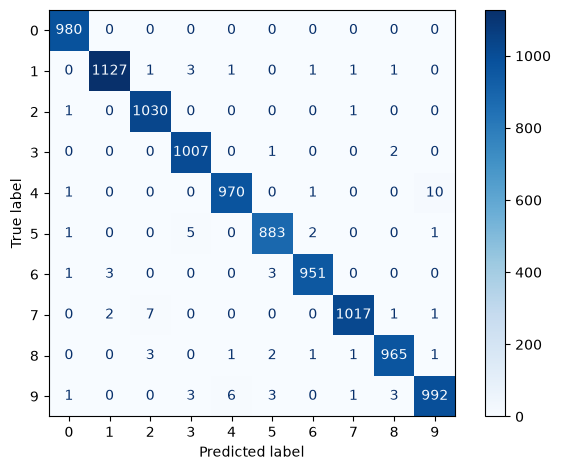

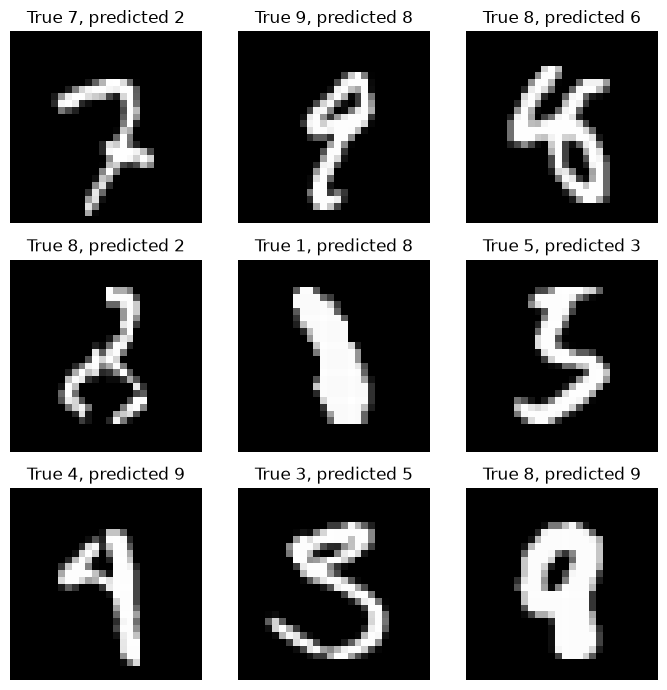

In [36]:
rows = [
    evaluate_keras(baseline, x_test, 'Dense baseline'),
    evaluate_keras(final_model, x_test_feat, 'Residual teacher'),
    evaluate_keras(pruned_model, x_test_feat, 'Pruned CNN'),
    evaluate_keras(student, x_test_feat, 'Distilled student'),
    evaluate_tflite(float_tflite, x_test_feat, 'Float TFLite'),
    evaluate_tflite(quantized_tflite, x_test_feat, 'Int8 TFLite'),
]
comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(OUTPUT_DIR / 'pipeline_comparison.csv')
comparison.to_json(OUTPUT_DIR / 'pipeline_results.json', orient='index', indent=2)
display(comparison.round(4))
predictions = final_model.predict(x_test_feat, verbose=0).argmax(axis=1)
print(classification_report(y_test, predictions, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap='Blues')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()
wrong = np.flatnonzero(predictions != y_test)[:9]
if len(wrong):
    fig, axes = plt.subplots(3, 3, figsize=(7, 7))
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, wrong):
        ax.imshow(x_test[index, ..., 0], cmap='gray')
        ax.set_title(f'True {y_test[index]}, predicted {predictions[index]}')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'misclassified_examples.png', dpi=150)
    plt.show()
